In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import matplotlib.pyplot as plt
import numpy as np
import zipfile, os, shutil, random
from google.colab import files
!pip install split-folders -q
import splitfolders

In [2]:
# 1. UPLOAD
print("Please upload your folder")
uploaded = files.upload()
zip_file = list(uploaded.keys())[0]

Please upload your folder


Saving Fruit_dataset.zip to Fruit_dataset.zip


In [3]:
# 2. EXTRACT
print("Extracting files...")
extract_path = 'dataset_raw'
if os.path.exists(extract_path): shutil.rmtree(extract_path)
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

Extracting files...


In [4]:
# 3. RESTRUCTURE & BALANCE DATASET
final_dataset_path = 'dataset_balanced'
if os.path.exists(final_dataset_path): shutil.rmtree(final_dataset_path)
os.makedirs(final_dataset_path, exist_ok=True)

# Find root folder automatically
root_dir = extract_path
for r, d, f in os.walk(extract_path):
    if 'Apple' in d:
        root_dir = r
        break

fruit_types = ['Apple', 'Banana', 'Strawberry']
statuses = ['Fresh', 'Rotten']

# Step 3A: Create the classes temporarily
temp_path = 'temp_all_classes'
if os.path.exists(temp_path): shutil.rmtree(temp_path)

print("Restructuring folders...")
valid_classes = []
for fruit in fruit_types:
    for status in statuses:
        old_dir = os.path.join(root_dir, fruit, status)
        new_class_name = f"{fruit}_{status}"
        new_dir = os.path.join(temp_path, new_class_name)

        if os.path.exists(old_dir):
            shutil.copytree(old_dir, new_dir)
            valid_classes.append(new_dir)
            print(f" Found class: {new_class_name}")

Restructuring folders...
 Found class: Apple_Fresh
 Found class: Apple_Rotten
 Found class: Banana_Fresh
 Found class: Banana_Rotten
 Found class: Strawberry_Fresh
 Found class: Strawberry_Rotten


In [5]:
# Step 3B: Balance the dataset (Equalize)

#[Image of histogram data distribution]

print("\n Balancing Dataset...")
counts = []
for d in valid_classes:
    num_files = len(os.listdir(d))
    counts.append(num_files)

if not counts:
    sys.exit(" Error: No image folders found.")

min_count = min(counts)
print(f" Minimum class count found is: {min_count}")
print(f" Trimming all classes to {min_count} images to ensure balance...")

for class_dir in valid_classes:
    class_name = os.path.basename(class_dir)
    final_class_dir = os.path.join(final_dataset_path, class_name)
    os.makedirs(final_class_dir, exist_ok=True)

    # Get all files and shuffle them to pick random ones
    all_files = os.listdir(class_dir)
    random.shuffle(all_files)

    # Select only min_count files
    selected_files = all_files[:min_count]

    for f in selected_files:
        shutil.copy(os.path.join(class_dir, f), os.path.join(final_class_dir, f))

print(" Dataset Balanced & Ready!")


 Balancing Dataset...
 Minimum class count found is: 33
 Trimming all classes to 33 images to ensure balance...
 Dataset Balanced & Ready!


In [6]:
# 4. SPLIT DATA
output_split = 'dataset_final_split'
splitfolders.ratio(final_dataset_path, output=output_split, seed=1337, ratio=(.7, .15, .15))

Copying files: 198 files [00:00, 2749.54 files/s]


In [7]:
# 5. DATA GENERATORS (Improved Augmentation)
img_size = (224, 224)
batch_size = 32

# Added brightness and shear because rot changes color and texture
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2], # NEW: helps with lighting differences
    shear_range=0.15,            # NEW: changes perspective slightly
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    f'{output_split}/train', target_size=img_size, batch_size=batch_size, class_mode='categorical'
)
val_generator = test_datagen.flow_from_directory(
    f'{output_split}/val', target_size=img_size, batch_size=batch_size, class_mode='categorical'
)
test_generator = test_datagen.flow_from_directory(
    f'{output_split}/test', target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=False
)

Found 123 images belonging to 6 classes.
Found 19 images belonging to 6 classes.
Found 34 images belonging to 6 classes.


In [8]:
# 6. BUILD MODEL
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

# Freeze base model initially
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x) # Reduced dropout slightly
predictions = Dense(6, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
# 7. TRAIN MODEL (Phase 1: Top Layers)
print("\n Phase 1: Training Top Layers...")
history = model.fit(
    train_generator,
    epochs=10, # Reduced initial epochs
    validation_data=val_generator
)


 Phase 1: Training Top Layers...
Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.4065 - loss: 1.7061 - val_accuracy: 0.8947 - val_loss: 0.4491
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7886 - loss: 0.5781 - val_accuracy: 1.0000 - val_loss: 0.1477
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.9106 - loss: 0.2514 - val_accuracy: 1.0000 - val_loss: 0.0658
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.9756 - loss: 0.1335 - val_accuracy: 1.0000 - val_loss: 0.0667
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.9268 - loss: 0.2273 - val_accuracy: 1.0000 - val_loss: 0.0213
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.9675 - loss: 0.1250 - val_accuracy: 1.0000 - val_loss: 0.0122
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.9593 - loss: 0.0991 - val_accuracy: 1.0000 - val_loss: 0.0148
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.9512 - loss: 0.1289 - val_accuracy: 1.0000

In [10]:
# 8. FINE TUNING (Phase 2: Improve Accuracy)
print("\n Phase 2: Fine Tuning (Unfreezing top layers of MobileNet)...")

# Unfreeze the base model
base_model.trainable = True

# Fine-tune only the top 40 layers (keeps basic shapes frozen, learns rot texture)
for layer in base_model.layers[:-40]:
    layer.trainable = False

# Recompile with a VERY LOW learning rate
model.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history_fine = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=[
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    ]
)


 Phase 2: Fine Tuning (Unfreezing top layers of MobileNet)...
Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 34s 5s/step - accuracy: 0.7805 - loss: 0.5653 - val_accuracy: 1.0000 - val_loss: 0.0060 - learning_rate: 1.0000e-05
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.7805 - loss: 0.5718 - val_accuracy: 1.0000 - val_loss: 0.0060 - learning_rate: 1.0000e-05
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8254 - loss: 0.4348
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
4/4 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.8211 - loss: 0.4498 - val_accuracy: 1.0000 - val_loss: 0.0061 - learning_rate: 1.0000e-05
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - accuracy: 0.8537 - loss: 0.4152 - val_accuracy: 1.0000 - val_loss: 0.0062 - learning_rate: 5.0000e-06
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9189 - loss: 0.2773
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
4/4 ━━━━━━━━━━━━━━━━━━━━ 1

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - accuracy: 0.8824 - loss: 0.3543



 Final Test Accuracy: 88.24%


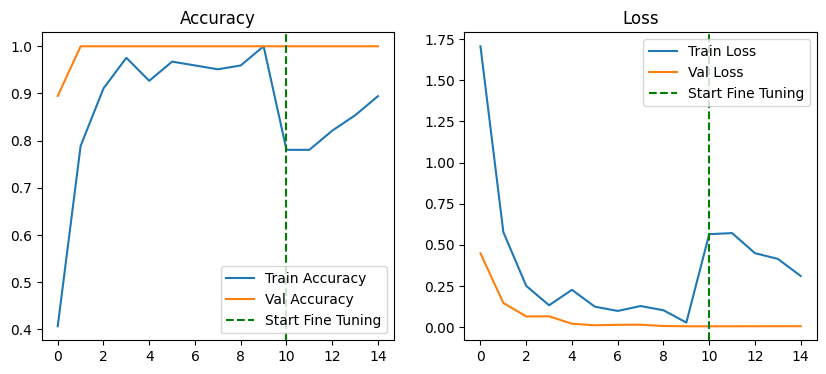

In [11]:
# 9. EVALUATION
loss, accuracy = model.evaluate(test_generator)
print(f'\n Final Test Accuracy: {accuracy*100:.2f}%')
model.save('MultiFruit_Freshness_Model_Balanced.h5')

# Merge histories for plotting
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.axvline(x=10, label='Start Fine Tuning', color='green', linestyle='--')
plt.title('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.axvline(x=10, label='Start Fine Tuning', color='green', linestyle='--')
plt.title('Loss')
plt.legend()
plt.show()


 Upload an images to test:


Saving apple_rotten_001.jpg (6).jpg to apple_rotten_001.jpg (6).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

 Fruit: Apple
MEASURED STATUS: Rotten (Confidence: 83.68%)


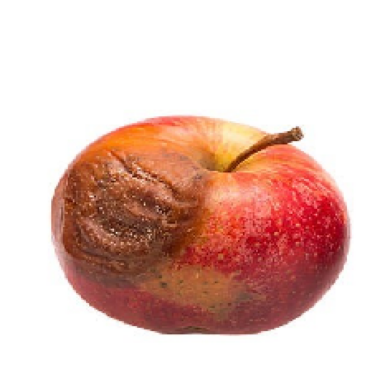

In [12]:
# 10. PREDICTION
def predict_image(img_path):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    pred = model.predict(img_array)
    idx = np.argmax(pred)
    full_label = list(train_generator.class_indices.keys())[idx]
    confidence = np.max(pred) * 100

    # Parse label
    parts = full_label.split('_')
    fruit = parts[0]
    status = parts[1]

    # Color code output
    color_code = '\033[92m' if status == 'Fresh' else '\033[91m' # Green for fresh, Red for rotten

    print(f"\n Fruit: {fruit}")
    print(f"{color_code}MEASURED STATUS: {status} (Confidence: {confidence:.2f}%)\033[0m")

    plt.imshow(img)
    plt.axis('off')
    plt.show()

print("\n Upload an images to test:")
uploaded_test = files.upload()
for f in uploaded_test.keys():
    predict_image(f)

In [13]:
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# --- 1. SETUP & LOGIC ---
class_labels = [
    'Apple_Fresh', 'Apple_Rotten',
    'Banana_Fresh', 'Banana_Rotten',
    'Strawberry_Fresh', 'Strawberry_Rotten'
]

# --- CORE PREDICTION LOGIC (Reused by both modes) ---
def get_prediction_data(img):
    # Resize and Preprocess
    img_resized = img.resize((224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img_resized)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    preds = model.predict(img_array)[0]
    top_idx = np.argmax(preds)
    top_label = class_labels[top_idx]
    confidence = preds[top_idx] * 100

    fruit, status = top_label.split('_')
    return fruit, status, confidence, preds

# --- FUNCTION 1: SINGLE IMAGE (Detailed Premium Badge) ---
def predict_single(img):
    if img is None: return None, None

    fruit, status, confidence, preds = get_prediction_data(img)
    clean_label = f"{fruit} {status}"

    # Chart Data (Top 1 only)
    single_result = {clean_label: float(preds[np.argmax(preds)])}

    # HTML Badge Construction
    if status == "Fresh":
        badge_html = f"""
        <div class="result-card fresh-card">
            <div class="icon-circle">🍃</div>
            <div class="text-content">
                <h3>Certified Fresh</h3>
                <h1>{fruit.upper()}</h1>
                <p>Confidence: <b>{confidence:.1f}%</b></p>
            </div>
        </div>
        """
    else:
        badge_html = f"""
        <div class="result-card rotten-card">
            <div class="icon-circle">☣️</div>
            <div class="text-content">
                <h3>Detected Rotten</h3>
                <h1>{fruit.upper()}</h1>
                <p>Confidence: <b>{confidence:.1f}%</b></p>
            </div>
        </div>
        """
    return single_result, badge_html

# --- FUNCTION 2: BATCH IMAGES (Gallery Grid) ---
def predict_batch(files):
    if not files: return None

    gallery_results = []

    # Loop through all uploaded files
    for file_obj in files:
        # Convert file path to PIL Image
        img = Image.open(file_obj)

        # Get prediction
        fruit, status, confidence, _ = get_prediction_data(img)

        # Create Caption with Emojis
        if status == "Fresh":
            caption = f"✅ {fruit} Fresh ({confidence:.0f}%)"
        else:
            caption = f"⚠️ {fruit} Rotten ({confidence:.0f}%)"

        # Append (Image, Caption) to gallery
        gallery_results.append((img, caption))

    return gallery_results

# --- 2. PREMIUM CSS STYLING ---
premium_css = """
@import url('https://fonts.googleapis.com/css2?family=Poppins:wght@300;400;600;800&display=swap');
.gradio-container { font-family: 'Poppins', sans-serif !important; }

/* Badge Styles (Single View) */
.result-card {
    padding: 25px; border-radius: 20px; display: flex; align-items: center; justify-content: center;
    gap: 20px; box-shadow: 0 10px 25px rgba(0,0,0,0.15); transition: transform 0.3s ease;
}
.result-card:hover { transform: scale(1.02); }
.fresh-card { background: linear-gradient(135deg, #11998e 0%, #38ef7d 100%); color: white; border: 2px solid white; }
.rotten-card { background: linear-gradient(135deg, #cb2d3e 0%, #ef473a 100%); color: white; border: 2px solid white; }
.text-content h1 { margin: 5px 0; font-size: 2.5rem; font-weight: 800; line-height: 1; }
.icon-circle { font-size: 3rem; background: rgba(255,255,255,0.2); padding: 15px; border-radius: 50%; }

/* Title */
#main-title { text-align: center; margin-bottom: 1rem; }
#main-title h1 {
    background: -webkit-linear-gradient(45deg, #FF512F, #DD2476);
    -webkit-background-clip: text; -webkit-text-fill-color: transparent;
    font-size: 3.5rem; font-weight: 800; margin: 0;
}
"""

# --- 3. UI CONSTRUCTION ---
theme = gr.themes.Default(primary_hue="orange", radius_size=gr.themes.sizes.radius_lg)

with gr.Blocks(theme=theme, css=premium_css, title="Fruit Freshness Classification") as demo:

    with gr.Row():
        gr.HTML("""<div id="main-title"><h1>Fruit Freshness Classification</h1></div>""")

    # --- TABS FOR DIFFERENT MODES ---
    with gr.Tabs():

        # TAB 1: SINGLE SCAN (Original Premium Design)
        with gr.TabItem("🔍 Single Scan"):
            with gr.Row():
                with gr.Column(scale=5):
                    with gr.Group():
                        img_input = gr.Image(type="pil", label="Analyze Single Sample", height=400, sources=['upload', 'clipboard', 'webcam'])
                        submit_btn = gr.Button("🚀 Scan Quality", variant="primary", size="lg")

                with gr.Column(scale=4):
                    verdict_output = gr.HTML(label="Quality Verdict")
                    chart_output = gr.Label(num_top_classes=1, label="Primary Detection")

            submit_btn.click(fn=predict_single, inputs=img_input, outputs=[chart_output, verdict_output])

        # TAB 2: BATCH SCAN (New Multi-Image Logic)
        with gr.TabItem("📚 Batch Scan"):
            gr.Markdown("### Upload multiple images to inspect an entire batch at once.")

            with gr.Row():
                # Input: Allows multiple files
                batch_input = gr.File(file_count="multiple", type="filepath", label="Upload Batch (Select Multiple)")
                batch_btn = gr.Button("🚀 Analyze All Images", variant="primary")

            # Output: Gallery Grid
            batch_output = gr.Gallery(label="Batch Results", columns=4, height=600, object_fit="contain")

            batch_btn.click(fn=predict_batch, inputs=batch_input, outputs=batch_output)

# Launch
demo.launch(share=True)

/tmp/ipykernel_1291/1592505077.py:118: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=theme, css=premium_css, title="Fruit Freshness Classification") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0b30fdbc956ee4ee27.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
